In [ ]:
#Importating Python libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split #We use this library to divide the dataset into training and testing
from sklearn.linear_model import LinearRegression #We use this library for Linear Regression
from sklearn.linear_model import LogisticRegression #Need this library for logistic regression
from sklearn.metrics import mean_squared_error #MSE is a model evaluation metric

#model evaluation metrics
import statsmodels.api as sm
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [ ]:
df = pd.read_csv('dataset_Facebook.csv', sep=';')

In [ ]:
df.head()

,Page total likes,Type,Category,Post Month,Post Weekday,Post Hour,Paid,Lifetime Post Total Reach,Lifetime Post Total Impressions,Lifetime Engaged Users,Lifetime Post Consumers,Lifetime Post Consumptions,Lifetime Post Impressions by people who have liked your Page,Lifetime Post reach by people who like your Page,Lifetime People who have liked your Page and engaged with your post,comment,like,share,Total Interactions
0,139441,Photo,2,12,4,3,0.0,2752,5091,178,109,159,3078,1640,119,4,79.0,17.0,100
1,139441,Status,2,12,3,10,0.0,10460,19057,1457,1361,1674,11710,6112,1108,5,130.0,29.0,164
2,139441,Photo,3,12,3,3,0.0,2413,4373,177,113,154,2812,1503,132,0,66.0,14.0,80
3,139441,Photo,2,12,2,10,1.0,50128,87991,2211,790,1119,61027,32048,1386,58,1572.0,147.0,1777
4,139441,Photo,2,12,2,3,0.0,7244,13594,671,410,580,6228,3200,396,19,325.0,49.0,393


Data Cleaning

In [ ]:
# Displays rows that have at least one missing value anywhere in the row
any_null_rows = df[df.isna().any(axis=1)]
print(any_null_rows)

     Page total likes   Type  Category  Post Month  Post Weekday  Post Hour  \
111            136736  Photo         1          10             6          8   
120            136393  Photo         1          10             7          9   
124            136393  Photo         1          10             7          6   
164            135428  Photo         1           9             5         10   
499             81370  Photo         2           1             4          4   

     Paid  Lifetime Post Total Reach  Lifetime Post Total Impressions  \
111   0.0                       1261                             2158   
120   0.0                        584                             1029   
124   0.0                        677                             1285   
164   0.0                       1060                             2004   
499   NaN                       4188                             7292   

     Lifetime Engaged Users  Lifetime Post Consumers  \
111                      37   

In [ ]:
# Remove rows where 'Paid' have missing values (NaN)
df = df.dropna(subset=['Paid'])

#Fill rows that have missing values in interaction types ('Comment', 'Like', 'Share') with 0
df['comment'] = df['comment'].fillna(0)
df['like'] = df['like'].fillna(0)
df['share'] = df['share'].fillna(0)

In [ ]:
#Creating new columns
df['Lifetime Post Impressions by people who have not liked your Page'] = df['Lifetime Post Total Impressions'] - df['Lifetime Post Impressions by people who have liked your Page']

df['Lifetime Post reach by people who do not like your Page'] = df['Lifetime Post Total Reach'] - df['Lifetime Post reach by people who like your Page']

df['Lifetime People who have not liked your Page and engaged with your post'] = df['Lifetime Engaged Users'] - df['Lifetime People who have liked your Page and engaged with your post']


df.head()

,Page total likes,Type,Category,Post Month,Post Weekday,Post Hour,Paid,Lifetime Post Total Reach,Lifetime Post Total Impressions,Lifetime Engaged Users,...,Lifetime Post Impressions by people who have liked your Page,Lifetime Post reach by people who like your Page,Lifetime People who have liked your Page and engaged with your post,comment,like,share,Total Interactions,Lifetime Post Impressions by people who have not liked your Page,Lifetime Post reach by people who do not like your Page,Lifetime People who have not liked your Page and engaged with your post
0,139441,Photo,2,12,4,3,0.0,2752,5091,178,...,3078,1640,119,4,79.0,17.0,100,2013,1112,59
1,139441,Status,2,12,3,10,0.0,10460,19057,1457,...,11710,6112,1108,5,130.0,29.0,164,7347,4348,349
2,139441,Photo,3,12,3,3,0.0,2413,4373,177,...,2812,1503,132,0,66.0,14.0,80,1561,910,45
3,139441,Photo,2,12,2,10,1.0,50128,87991,2211,...,61027,32048,1386,58,1572.0,147.0,1777,26964,18080,825
4,139441,Photo,2,12,2,3,0.0,7244,13594,671,...,6228,3200,396,19,325.0,49.0,393,7366,4044,275


Descriptive Statistics

In [ ]:
# Descriptive Statistics Analysis

print("Dataset Shape:")
print(df.shape)

print("\nNumeric Variable Summary:")
print(df.describe())

print("\nCategorical Variable Summary:")
print(df[['Type','Category','Paid']].describe())

print("\nPost Type Distribution:")
print(df['Type'].value_counts())

print("\nPaid vs Unpaid Posts:")
print(df['Paid'].value_counts())

print("\nMean Total Interactions:")
print(df['Total Interactions'].mean())

print("\nMedian Total Interactions:")
print(df['Total Interactions'].median())

print("\nStandard Deviation of Total Interactions:")
print(df['Total Interactions'].std())

Dataset Shape:
(499, 22)

Numeric Variable Summary:
       Page total likes    Category  Post Month  Post Weekday   Post Hour  \
count        499.000000  499.000000   499.00000    499.000000  499.000000   
mean      123277.991984    1.879760     7.05010      4.150301    7.847695   
std        16180.746980    0.853513     3.30016      2.032728    4.369579   
min        81370.000000    1.000000     1.00000      1.000000    1.000000   
25%       113028.000000    1.000000     4.00000      2.000000    3.000000   
50%       129600.000000    2.000000     7.00000      4.000000    9.000000   
75%       136393.000000    3.000000    10.00000      6.000000   11.000000   
max       139441.000000    3.000000    12.00000      7.000000   23.000000   

             Paid  Lifetime Post Total Reach  Lifetime Post Total Impressions  \
count  499.000000                 499.000000                     4.990000e+02   
mean     0.278557               13922.829659                     2.963063e+04   
std      0.

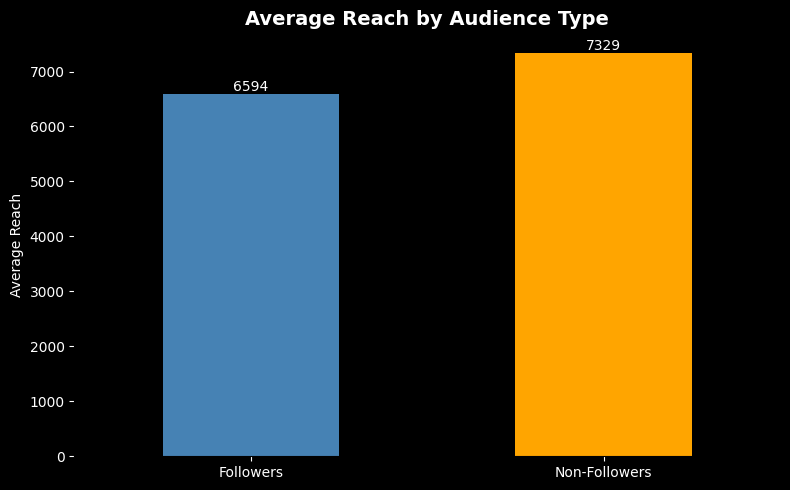

In [ ]:
#Average Reach by Audience Type Chart
reach_compare = df[[
    'Lifetime Post reach by people who like your Page',
    'Lifetime Post reach by people who do not like your Page'
]]

mean_reach = reach_compare.mean()



mean_reach.index = ['Followers', 'Non-Followers']

# Create figure
fig, ax = plt.subplots(figsize=(8,5))

# Black background
fig.patch.set_facecolor('black')
ax.set_facecolor('black')

# Bar Chart
mean_reach.plot(
    kind='bar',
    color=['steelblue', 'orange'],
    ax=ax
)

# Formatting
ax.set_title('Average Reach by Audience Type',
             color='white',
             fontsize=14,
             weight='bold')

ax.set_ylabel('Average Reach', color='white')

ax.tick_params(axis='x', colors='white')
ax.tick_params(axis='y', colors='white')

for container in ax.containers:
    ax.bar_label(container,
                 fmt='%.0f',
                 color='white')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

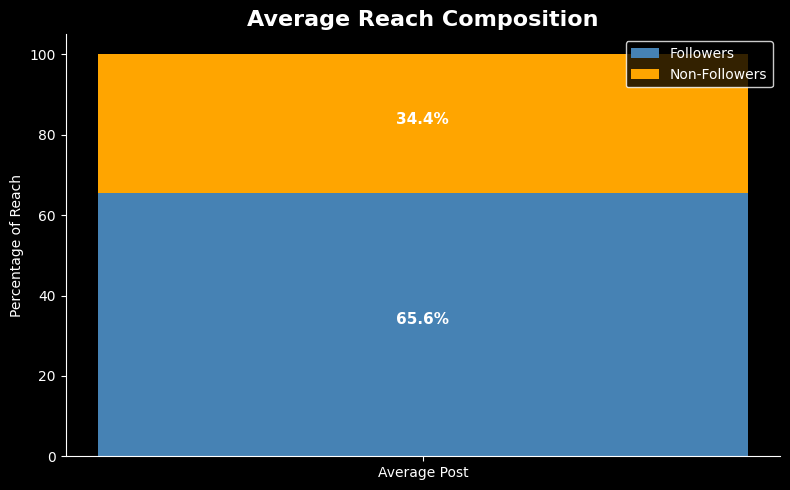

Follower %        65.60196
Non-Follower %    34.39804
dtype: float64


In [ ]:
#Average Reach Composition Chart
reach_pct = pd.DataFrame({
    'Follower %':
        df['Lifetime Post reach by people who like your Page'] /
        df['Lifetime Post Total Reach'] * 100,

    'Non-Follower %':
        df['Lifetime Post reach by people who do not like your Page'] /
        df['Lifetime Post Total Reach'] * 100
})

avg_pct = reach_pct.mean()

# Create figure
fig, ax = plt.subplots(figsize=(8,5))

# Black background
fig.patch.set_facecolor('black')
ax.set_facecolor('black')

# Stacked bar
ax.bar(
    ['Average Post'],
    [avg_pct['Follower %']],
    color='steelblue',
    label='Followers'
)

ax.bar(
    ['Average Post'],
    [avg_pct['Non-Follower %']],
    bottom=[avg_pct['Follower %']],
    color='orange',
    label='Non-Followers'
)

# Add percentage labels
ax.text(
    0,
    avg_pct['Follower %']/2,
    f"{avg_pct['Follower %']:.1f}%",
    ha='center',
    color='white',
    fontsize=11,
    weight='bold'
)

ax.text(
    0,
    avg_pct['Follower %'] + avg_pct['Non-Follower %']/2,
    f"{avg_pct['Non-Follower %']:.1f}%",
    ha='center',
    color='white',
    fontsize=11,
    weight='bold'
)

# Formatting
ax.set_ylabel('Percentage of Reach', color='white')
ax.set_title(
    'Average Reach Composition',
    color='white',
    fontsize=16,
    weight='bold'
)

ax.tick_params(axis='x', colors='white')
ax.tick_params(axis='y', colors='white')

ax.legend(facecolor='black', edgecolor='white', labelcolor='white')

ax.spines['bottom'].set_color('white')
ax.spines['left'].set_color('white')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

print(avg_pct)

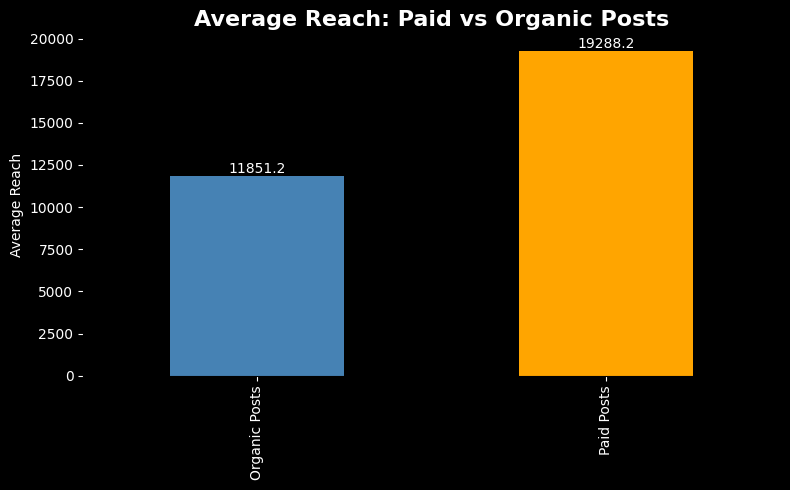

In [ ]:
#Average Reach by Type
paid_reach = df.groupby('Paid')['Lifetime Post Total Reach'].mean()

fig, ax = plt.subplots(figsize=(8,5))

fig.patch.set_facecolor('black')
ax.set_facecolor('black')

paid_reach.index = ['Organic Posts', 'Paid Posts']

# Bar Chart
paid_reach.plot(
    kind='bar',
    color=['steelblue', 'orange'],
    ax=ax
)

# Formatting
ax.set_title(
    'Average Reach: Paid vs Organic Posts',
    color='white',
    fontsize=16,
    weight='bold'
)

ax.set_ylabel('Average Reach', color='white')

ax.tick_params(colors='white')

for container in ax.containers:
    ax.bar_label(container, color='white')

plt.tight_layout()
plt.show()

Regression Model 1

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Dummy-code Type and Category (drop_first avoids the dummy variable trap)
X = pd.get_dummies(df[['Paid', 'Type', 'Category']],
                   columns=['Type', 'Category'], drop_first=True).astype(float)
y = np.log1p(df['Total Interactions'])

X2 = sm.add_constant(X)
model1 = sm.OLS(y, X2).fit(cov_type='HC3')
print(model1.summary())

# VIF (ignore the row for 'const')
vif_data = pd.DataFrame({
    'feature': X2.columns,
    'VIF': [variance_inflation_factor(X2.values, i) for i in range(X2.shape[1])]
})
print("The VIF numbers are:\n", vif_data)

                            OLS Regression Results                            
Dep. Variable:     Total Interactions   R-squared:                       0.160
Model:                            OLS   Adj. R-squared:                  0.149
Method:                 Least Squares   F-statistic:                     13.06
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           9.76e-14
Time:                        17:17:46   Log-Likelihood:                -757.30
No. Observations:                 499   AIC:                             1529.
Df Residuals:                     492   BIC:                             1558.
Df Model:                           6                                         
Covariance Type:                  HC3                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           3.8398      0.245     15.680      

Regression Model 2: Holding reach and timing constant, which factors drive interactions?

In [ ]:
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

df['log_interactions'] = np.log1p(df['Total Interactions'])
df['log_reach'] = np.log1p(df['Lifetime Post Total Reach'])
df['page_likes_k'] = df['Page total likes'] / 1000   # per 1,000 likes, easier to read

X = pd.get_dummies(df[['Paid', 'Type', 'Category', 'Post Weekday', 'Post Hour',
                       'page_likes_k', 'log_reach']],
                   columns=['Type', 'Category', 'Post Weekday'],
                   drop_first=True).astype(float)
y = df['log_interactions']

X2 = sm.add_constant(X)
model2 = sm.OLS(y, X2).fit(cov_type='HC3')   # robust standard errors
print(model2.summary())

vif_data = pd.DataFrame({'feature': X2.columns,
    'VIF': [variance_inflation_factor(X2.values, i) for i in range(X2.shape[1])]})
print(vif_data)

                            OLS Regression Results                            
Dep. Variable:       log_interactions   R-squared:                       0.647
Model:                            OLS   Adj. R-squared:                  0.636
Method:                 Least Squares   F-statistic:                     37.42
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           4.36e-71
Time:                        17:17:46   Log-Likelihood:                -540.77
No. Observations:                 499   AIC:                             1114.
Df Residuals:                     483   BIC:                             1181.
Df Model:                          15                                         
Covariance Type:                  HC3                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -4.4877      0.557     -8.

Charts

In [ ]:
# ---------- Shared style ----------
BG, FG, GRAY = 'black', 'white', '#777777'
ORANGE, BLUE = '#FFA500', '#4682B4'

def dark(ax, fig):
    fig.patch.set_facecolor(BG); ax.set_facecolor(BG)
    ax.tick_params(colors=FG, labelsize=12)
    for s in ['top', 'right']: ax.spines[s].set_visible(False)
    for s in ['bottom', 'left']: ax.spines[s].set_color(GRAY)

nice = {'Paid': 'Paid post', 'Type_Photo': 'Photo', 'Type_Status': 'Status',
        'Type_Video': 'Video', 'Category_2': 'Category 2', 'Category_3': 'Category 3',
        'Post Weekday_7': 'Weekday 7 (vs. 1)', 'Post Hour': 'Post hour (+1 hr)',
        'page_likes_k': 'Page likes (+1,000)', 'log_reach': 'Reach (+10%)'}

def effect_bars(model, features, title, subtitle, fname):
    """Simple bar chart: % change in interactions for each feature."""
    pct, sig = [], []
    for f in features:
        b = model.params[f]
        if f == 'log_reach':                 # elasticity -> effect of +10% reach
            b = b * np.log(1.10)
        pct.append((np.exp(b) - 1) * 100)
        sig.append(model.pvalues[f] < 0.05)
    labels = [nice[f] for f in features]
    order = np.argsort(pct)
    fig, ax = plt.subplots(figsize=(10, 5.5)); dark(ax, fig)
    bars = ax.barh([labels[i] for i in order], [pct[i] for i in order],
                   color=[ORANGE if sig[i] else GRAY for i in order], height=0.6)
    for b, i in zip(bars, order):
        x = b.get_width()
        # negative bars get their label on the right of the zero line so it never hits the axis labels
        ax.text(max(x, 0) + 4, b.get_y() + b.get_height()/2,
                f"{pct[i]:+.0f}%", va='center', ha='left',
                color=FG, fontsize=13, weight='bold')
    ax.axvline(0, color=FG, lw=1)
    lo, hi = min(pct), max(pct)
    ax.set_xlim(min(lo * 1.4, -20), hi * 1.18)
    ax.set_xlabel('% change in total interactions', color=FG, fontsize=12)
    ax.set_title(title, color=FG, fontsize=20, weight='bold', loc='left', pad=30)
    ax.text(0, 1.03, subtitle, transform=ax.transAxes, color=GRAY, fontsize=11)
    plt.tight_layout(); plt.savefig(fname, dpi=200, facecolor=BG); plt.show()

# ---------- Model 1 effects ----------
effect_bars(model1,
            ['Paid', 'Type_Photo', 'Type_Status', 'Type_Video', 'Category_2', 'Category_3'],
            'Model 1: What gets more engagement?',
            'Orange = significant (p < .05), gray = not significant  ·  vs. organic, link, category 1',
            'A_model1_effects.png')
# ---------- Model 2 effects ----------
effect_bars(model2,
            ['Paid', 'Type_Photo', 'Type_Video', 'Category_2', 'Category_3',
             'log_reach', 'page_likes_k', 'Post Weekday_7', 'Post Hour'],
            'Model 2: Holding reach constant',
            'Orange = significant (p < .05), gray = not significant  ·  paid effect is no longer significant',
            'D_model2_effects.png')

print(f"Model 1 R² = {model1.rsquared:.3f} | Model 2 R² = {model2.rsquared:.3f} | r(reach, interactions) = {r:.2f}")

Logistic Regression

In [ ]:
#Logsitical Regression on just paid ads
paid_posts = df[df['Paid'] == 1].copy()

# Calculate threshold
threshold = paid_posts['Total Interactions'].median()

print("Successful Ad Threshold:", threshold)

# Create binary target
paid_posts['successful_ad'] = (
    paid_posts['Total Interactions'] > threshold
).astype(int)

# Create time-of-day categories
def time_period(hour):
    if hour < 12:
        return "Morning"
    elif hour < 17:
        return "Afternoon"
    else:
        return "Evening"

paid_posts['Time_Period'] = paid_posts['Post Hour'].apply(time_period)

# Check class distribution
print(paid_posts['successful_ad'].value_counts(normalize=True))

Successful Ad Threshold: 158.0
successful_ad
0    0.503597
1    0.496403
Name: proportion, dtype: float64


In [ ]:
#Using the features from the our regression
features = [
    'Type',
    'Category',
    'Time_Period',
    'Post Weekday',
    'Post Month',
]

model_df = paid_posts[features + ['successful_ad']].copy()

#Dummy variables
X = pd.get_dummies(
    model_df[features],
    columns=['Type', 'Category','Time_Period'],
    drop_first=True,
    dtype=float
)

y = model_df['successful_ad']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20, #You can do a 70-30 split or 75-25 split
    random_state=42,
    stratify=y
)


#Fit the logistic regression model


logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

logistic_model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [ ]:
#Print the intercept (bias term)
print("Intercept:", logistic_model.intercept_[0])


# If X is a pandas DataFrame, feature names are in X.columns
coefficients = pd.DataFrame(
    {"Feature": X.columns, "Coefficient": logistic_model.coef_[0]}
)

# Sort by absolute impact/importance
coefficients["Abs_Coefficient"] = coefficients["Coefficient"].abs()
coefficients = coefficients.sort_values(by="Abs_Coefficient", ascending=False)

print("\nLogistic Regression Coefficients:")
print(coefficients[["Feature", "Coefficient"]].to_string(index=False))

Intercept: -0.2552362882065643

Logistic Regression Coefficients:
            Feature  Coefficient
         Category_3     0.525756
        Type_Status     0.470764
         Category_2     0.332224
Time_Period_Evening    -0.331037
         Type_Video     0.299803
         Type_Photo    -0.100833
       Post Weekday    -0.099037
Time_Period_Morning     0.062468
         Post Month     0.059492


In [ ]:
#Add the intercept
X_train_const = sm.add_constant(X_train)

#Fit the logistic regression model
logit_model = sm.Logit(
    y_train,
    X_train_const
).fit(maxiter=500)

# Print the summary with coefficients and p-values
print(logit_model.summary())

         Current function value: 0.661806
         Iterations: 500
                           Logit Regression Results                           
Dep. Variable:          successful_ad   No. Observations:                  111
Model:                          Logit   Df Residuals:                      101
Method:                           MLE   Df Model:                            9
Date:                Sat, 17 Oct 2026   Pseudo R-squ.:                 0.04516
Time:                        17:17:48   Log-Likelihood:                -73.460
converged:                      False   LL-Null:                       -76.935
Covariance Type:            nonrobust   LLR p-value:                    0.6425
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  -1.0433      1.446     -0.722      0.471      -3.877       1.791
Post Weekday           -0.0930      0

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [ ]:
#Okay, now we are back to our prediction task with scikit-learn
#Training predictions

y_train_pred = logistic_model.predict(X_train)

print("Training Accuracy:")
print(accuracy_score(y_train, y_train_pred))

print("\nTraining Confusion Matrix:")
print(confusion_matrix(y_train, y_train_pred))

#You can also print the confusion matrix in a more readable format


# Calculate confusion matrix
cm = confusion_matrix(y_train, y_train_pred)

# Add descriptive row and column labels
cm_table = pd.DataFrame(
    cm,
    index=[
        'Actual 0: Non-Successful Ad',
        'Actual 1: Successful Ad'
    ],
    columns=[
        'Predicted 0: Non-Successful Ad',
        'Predicted 1: Successful Ad'
    ]
)

print("Training Confusion Matrix:")
print(cm_table)

print("\nTraining Classification Report:")
print(classification_report(y_train, y_train_pred))



Training Accuracy:
0.5945945945945946

Training Confusion Matrix:
[[33 23]
 [22 33]]
Training Confusion Matrix:
                             Predicted 0: Non-Successful Ad  \
Actual 0: Non-Successful Ad                              33   
Actual 1: Successful Ad                                  22   

                             Predicted 1: Successful Ad  
Actual 0: Non-Successful Ad                          23  
Actual 1: Successful Ad                              33  

Training Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.59      0.59        56
           1       0.59      0.60      0.59        55

    accuracy                           0.59       111
   macro avg       0.59      0.59      0.59       111
weighted avg       0.59      0.59      0.59       111



In [ ]:
#Generate predictions for the test data
y_pred = logistic_model.predict(X_test)

# Probability that an ad is successful
y_probability = logistic_model.predict_proba(X_test)[:, 1]

In [ ]:
#Now, we evaluate the model performance

print("Testing Accuracy:")
print(accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Testing Accuracy:
0.6785714285714286

Confusion Matrix:
[[ 9  5]
 [ 4 10]]

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.64      0.67        14
           1       0.67      0.71      0.69        14

    accuracy                           0.68        28
   macro avg       0.68      0.68      0.68        28
weighted avg       0.68      0.68      0.68        28



In [ ]:
#Display some of the results
prediction_results = pd.DataFrame({
    'Actual Class': y_test,
    'Predicted Class': y_pred,
    'Probability of Successful Ad': y_probability
})

print(prediction_results.head(10))

     Actual Class  Predicted Class  Probability of Successful Ad
176             1                1                      0.543232
182             1                1                      0.615495
374             0                0                      0.374198
414             1                0                      0.360374
190             0                1                      0.638650
180             1                1                      0.679070
43              0                1                      0.506488
301             0                0                      0.498721
198             0                0                      0.446750
473             1                1                      0.538192


K Means

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# ---------- Setup: dark slide style + tier colors ----------
plt.rcParams.update({
    'figure.facecolor': 'black', 'axes.facecolor': 'black',
    'axes.edgecolor': '#555555', 'axes.labelcolor': 'white',
    'xtick.color': 'white', 'ytick.color': 'white',
    'text.color': 'white', 'legend.frameon': False,
})
tier_names  = ['Low performers', 'Average performers', 'High performers']
tier_colors = {'Low performers': '#8c8c8c',
               'Average performers': '#4f81bd',
               'High performers': '#f2a93b'}

# ---------- Clustering ----------
cluster_features = ['Lifetime Post Total Reach', 'Lifetime Post Total Impressions',
                    'Lifetime Engaged Users', 'Lifetime Post Consumers',
                    'Total Interactions']
X_scaled = StandardScaler().fit_transform(np.log1p(df[cluster_features]))

km = KMeans(n_clusters=3, n_init=10, random_state=42)
df['cluster'] = km.fit_predict(X_scaled)
rank = df.groupby('cluster')['Total Interactions'].median().sort_values().index
df['cluster_name'] = df['cluster'].map(dict(zip(rank, tier_names)))

# ---------- Chart 1: Elbow method ----------
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled).inertia_
           for k in range(1, 11)]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(range(1, 11), inertia, marker='o', color='#4f81bd')
ax.scatter(3, inertia[2], s=140, color='#f2a93b', zorder=3)
ax.annotate('k = 3\n(the bend)', xy=(3, inertia[2]), xytext=(4, inertia[2] + 400),
            color='#f2a93b', arrowprops=dict(arrowstyle='->', color='#f2a93b'))
ax.set_xticks(range(1, 11))
ax.set_xlabel('Number of clusters (k)')
ax.set_ylabel('Inertia (within-cluster spread)')
ax.set_title('Elbow method', fontweight='bold')
plt.show()

# ---------- Chart 2: PCA scatter ----------
coords = PCA(n_components=2).fit_transform(X_scaled)
# flip PC1 if needed so "right" = better performance
if np.corrcoef(coords[:, 0], np.log1p(df['Total Interactions']))[0, 1] < 0:
    coords[:, 0] *= -1

fig, ax = plt.subplots(figsize=(9, 5))
for name in tier_names:
    mask = (df['cluster_name'] == name).values
    ax.scatter(coords[mask, 0], coords[mask, 1], s=14, alpha=0.8,
               color=tier_colors[name], label=name)
ax.set_xlabel('Overall performance →  (PC1)')
ax.set_ylabel('PC2')
ax.set_title('Three distinct performance tiers', loc='left', fontweight='bold', pad=22)
ax.text(0, 1.02, 'Each dot is a post, positioned by reach + engagement metrics (PCA)',
        transform=ax.transAxes, color='#999999', fontsize=9)
ax.legend()
plt.show()

# ---------- Reusable stacked bar function (Charts 3-5) ----------
def tier_bar(group_col, labels, title, order=None):
    pct = pd.crosstab(df[group_col], df['cluster_name'], normalize='index')[tier_names] * 100
    n = df[group_col].value_counts()
    if order is not None:
        pct, n = pct.loc[order], n.loc[order]
    pct = pct.iloc[::-1]   # so the first item in `order` appears on top
    ylabels = [f'{labels.get(i, i)}  (n={n[i]})' for i in pct.index]

    fig, ax = plt.subplots(figsize=(9, 0.9 * len(pct) + 1.5))
    left = np.zeros(len(pct))
    for name in tier_names:
        vals = pct[name].values
        ax.barh(ylabels, vals, left=left, color=tier_colors[name], label=name, height=0.6)
        for y, (l, v) in enumerate(zip(left, vals)):
            if v >= 5:   # skip labels on tiny segments
                ax.text(l + v / 2, y, f'{v:.0f}%', ha='center', va='center',
                        color='black', fontsize=9)
        left += vals
    ax.set_xlim(0, 100)
    ax.set_xlabel('% of posts in each tier')
    ax.set_title(title, fontweight='bold')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=3)
    plt.show()

# ---------- Chart 3: Paid vs Organic ----------
tier_bar('Paid', {1.0: 'Paid', 0.0: 'Organic'}, 'Who lands in each tier?', order=[1.0, 0.0])

# ---------- Chart 4: By post type ----------
tier_bar('Type', {}, 'Links are the weakest format', order=['Video', 'Status', 'Photo', 'Link'])

# ---------- Chart 5: By category ----------
tier_bar('Category', {1: 'Category 1', 2: 'Category 2', 3: 'Category 3'},
         'Category 1 has the most low performers', order=[3, 2, 1])